In [138]:

import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Path to the new SpO2 folder
SPO2_PATH = Path("../data/data/raw/spo2")

records = [
    "a01", "a02", "a03", "a04",
    "b01", "c01", "c02", "c03"
]

print("SpO2 folder exists:", SPO2_PATH.exists())
print("Number of records:", len(records))


SpO2 folder exists: True
Number of records: 8


In [139]:

spo2_data = {}

for name in records:

    record_name = name + "r"

    # Load recording
    record = wfdb.rdrecord(str(SPO2_PATH / record_name))

    print("\n", "=" * 45)
    print("Record:", record_name)
    print("Sampling frequency:", record.fs)
    print("Signal shape:", record.p_signal.shape)
    print("Channels:", record.sig_name)
    print("Units:", record.units)

    # Identify SpO2 channel
    spo2_index = next(
        (
            i for i, channel in enumerate(record.sig_name)
            if "spo2" in channel.lower()
        ),
        None
    )

    if spo2_index is None:
        print("SpO2 channel not found!")
        continue

    spo2 = record.p_signal[:, spo2_index]

    # Store signal and metadata
    spo2_data[name] = {
        "signal": spo2,
        "fs": record.fs,
        "units": record.units[spo2_index]
    }

    valid = spo2[np.isfinite(spo2)]

    print("Total samples:", len(spo2))
    print("Duration (hours):", len(spo2) / record.fs / 3600)
    print("Valid samples:", len(valid))
    print("Missing samples:", np.sum(~np.isfinite(spo2)))

    if len(valid):
        print("Minimum SpO2:", np.min(valid))
        print("Maximum SpO2:", np.max(valid))
        print("Mean SpO2:", np.mean(valid))



Record: a01r
Sampling frequency: 100
Signal shape: (2956796, 4)
Channels: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Total samples: 2956796
Duration (hours): 8.213322222222223
Valid samples: 2956796
Missing samples: 0
Minimum SpO2: 0.0
Maximum SpO2: 100.0
Mean SpO2: 89.54318458223023

Record: a02r
Sampling frequency: 100
Signal shape: (3181796, 4)
Channels: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Total samples: 3181796
Duration (hours): 8.838322222222223
Valid samples: 3181796
Missing samples: 0
Minimum SpO2: 0.0
Maximum SpO2: 100.0
Mean SpO2: 85.20059362699557

Record: a03r
Sampling frequency: 100
Signal shape: (3134796, 4)
Channels: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Total samples: 3134796
Duration (hours): 8.707766666666666
Valid samples: 3134796
Missing samples: 0
Minimum SpO2: 0.0
Maximum SpO2: 98.0
Mean SpO2: 90.04029704006257

Record: a04r
Sampling frequency: 100
Signal shape: (297979

In [140]:

from pathlib import Path
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles inside the expected SpO2 folder:")

SPO2_PATH = Path("../data/data/raw/spo2")

print("Folder exists:", SPO2_PATH.exists())

if SPO2_PATH.exists():
    for file in sorted(SPO2_PATH.iterdir()):
        print(file.name)


Current working directory:
C:\Users\navee\sleep-apnea-signal-analysis\notebooks

Files inside the expected SpO2 folder:
Folder exists: True
a01r.apn
a01r.dat
a01r.hea
a02r.apn
a02r.dat
a02r.hea
a03r.apn
a03r.dat
a03r.hea
a04r.apn
a04r.dat
a04r.hea
b01r.apn
b01r.dat
b01r.hea
c01r.apn
c01r.dat
c01r.hea
c02r.apn
c02r.dat
c02r.hea
c03r.apn
c03r.dat
c03r.hea


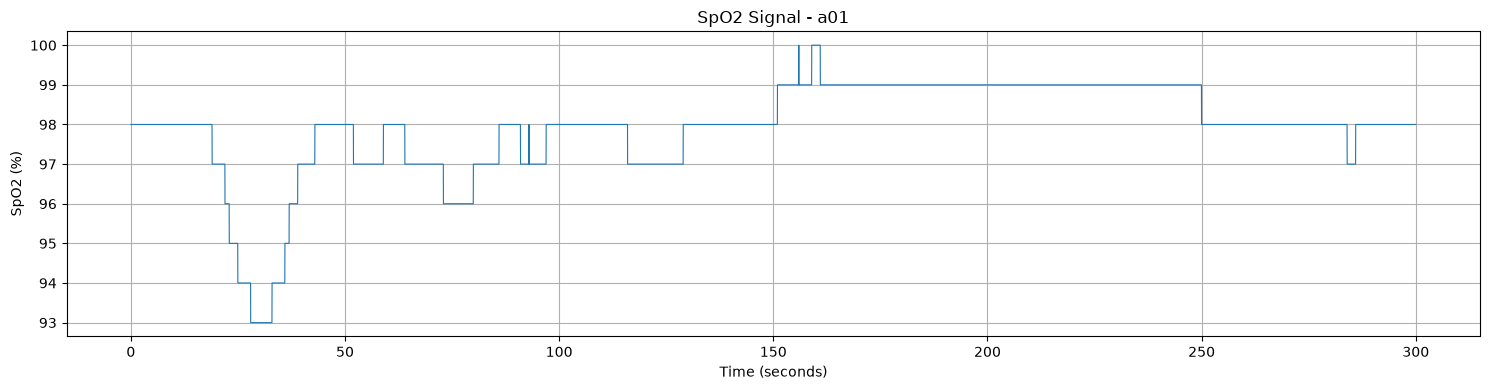

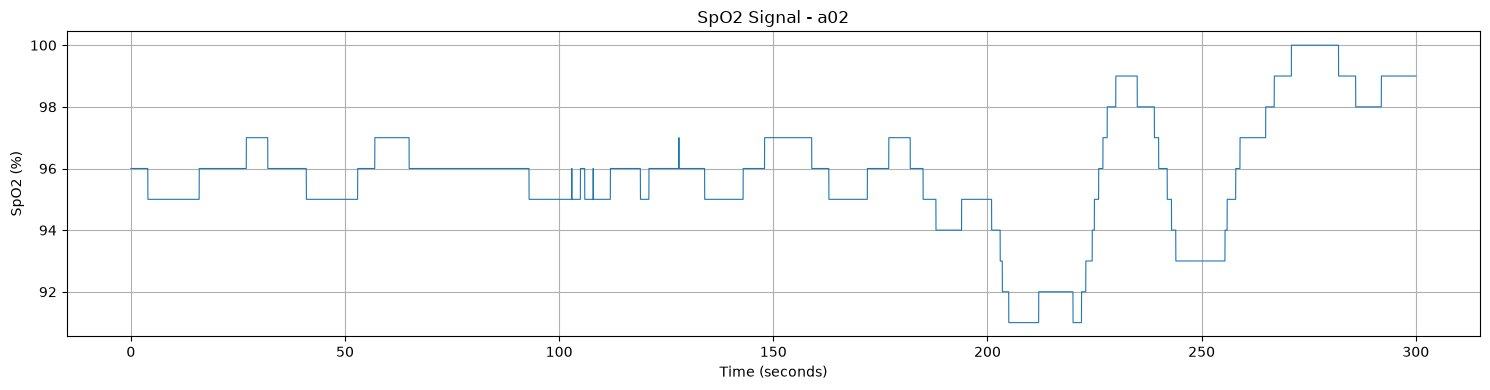

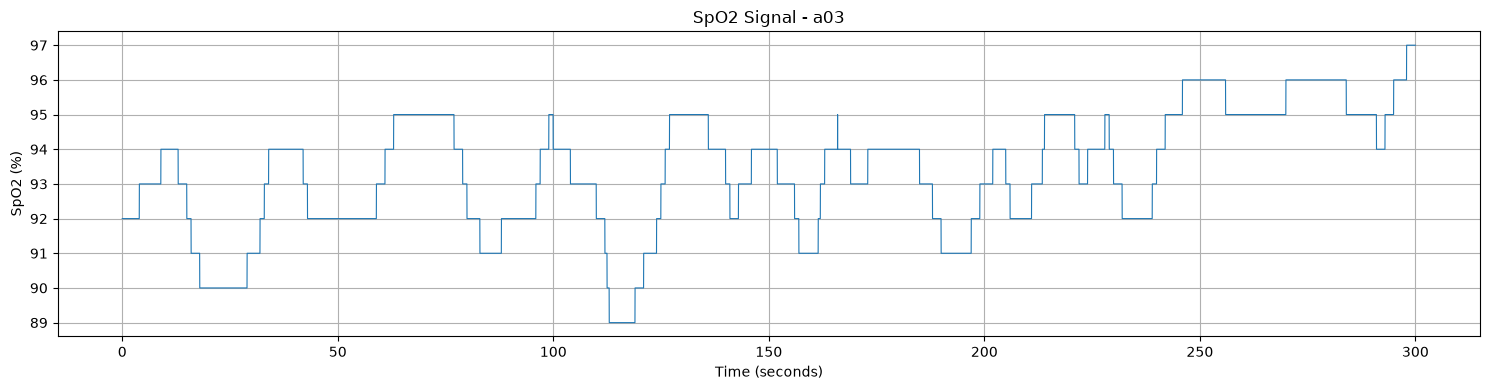

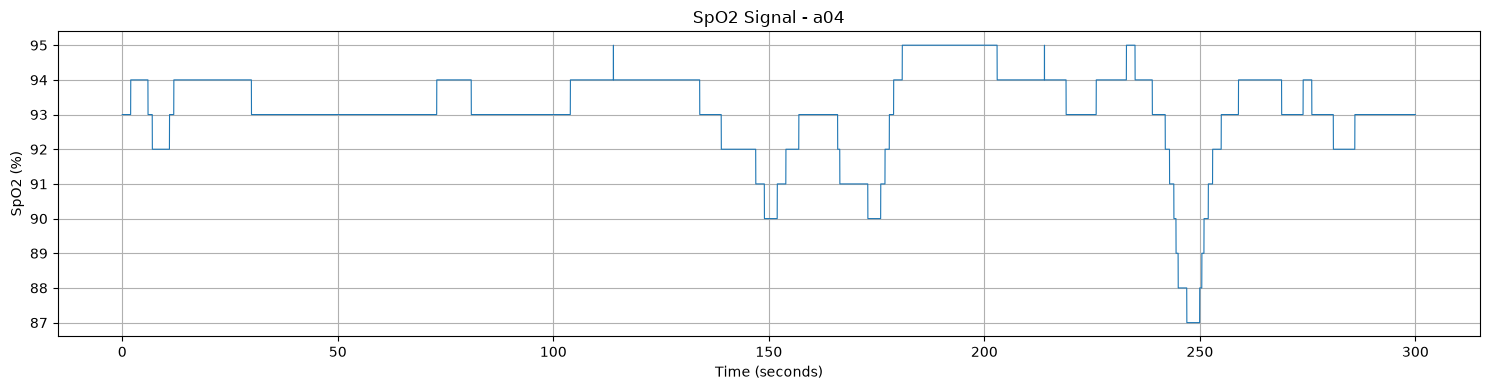

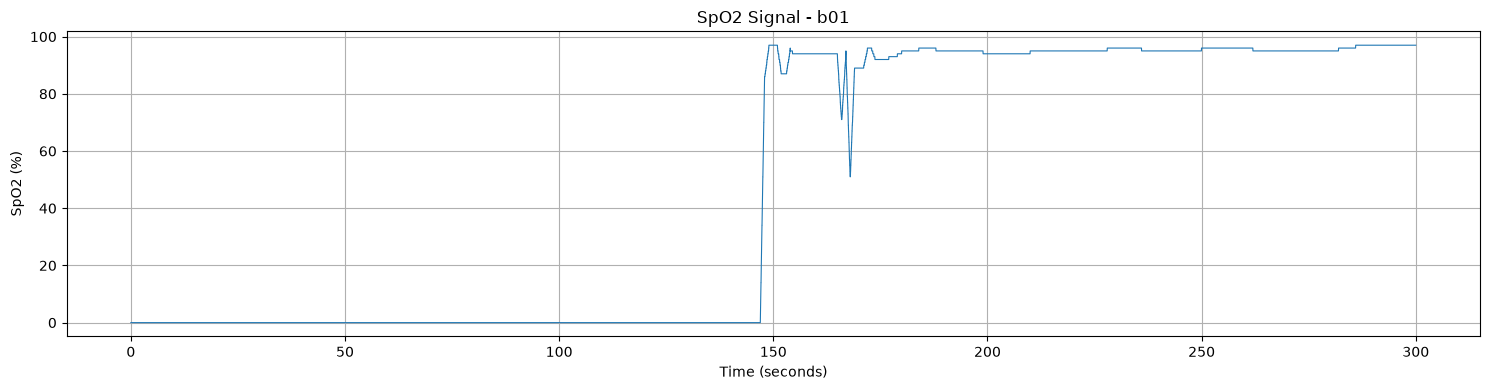

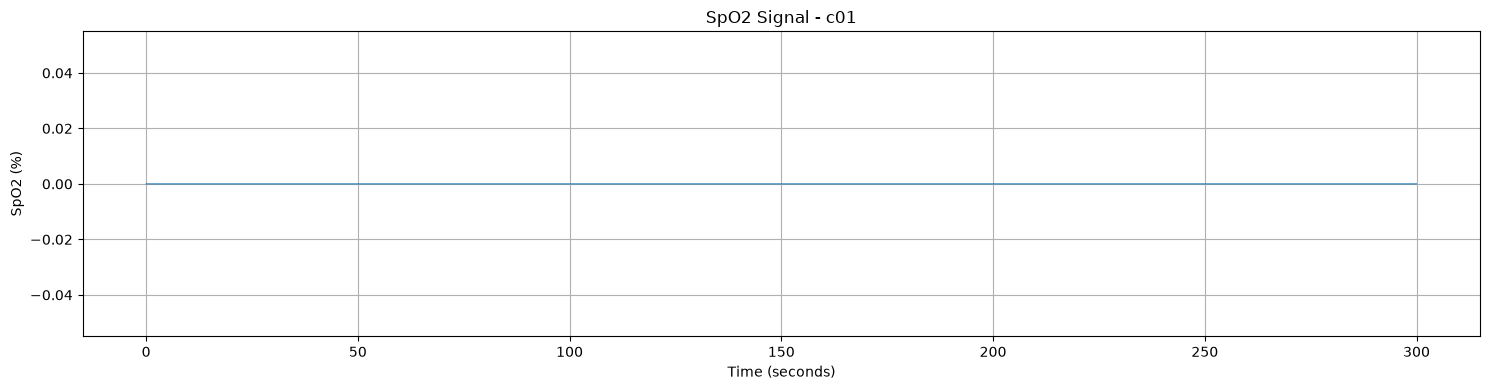

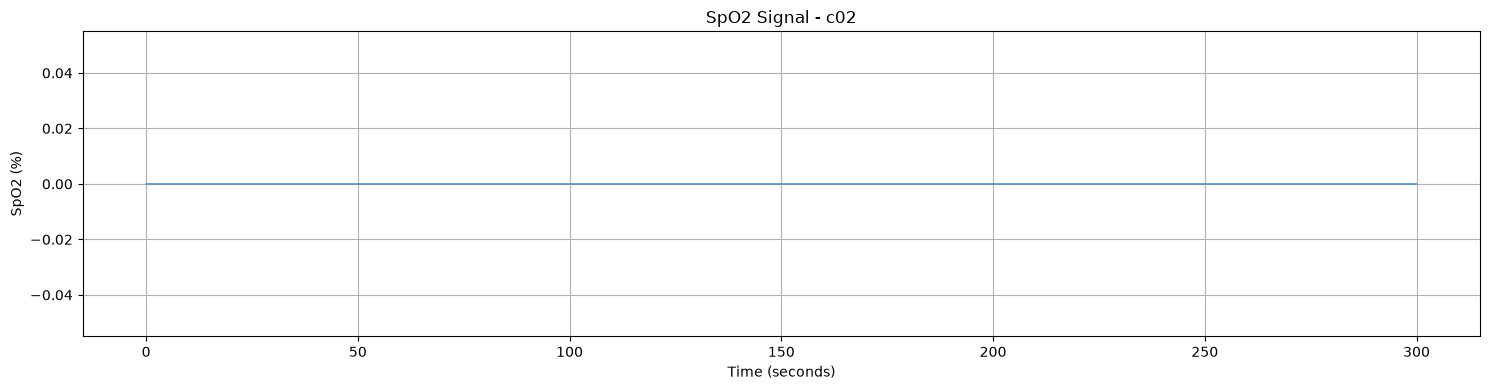

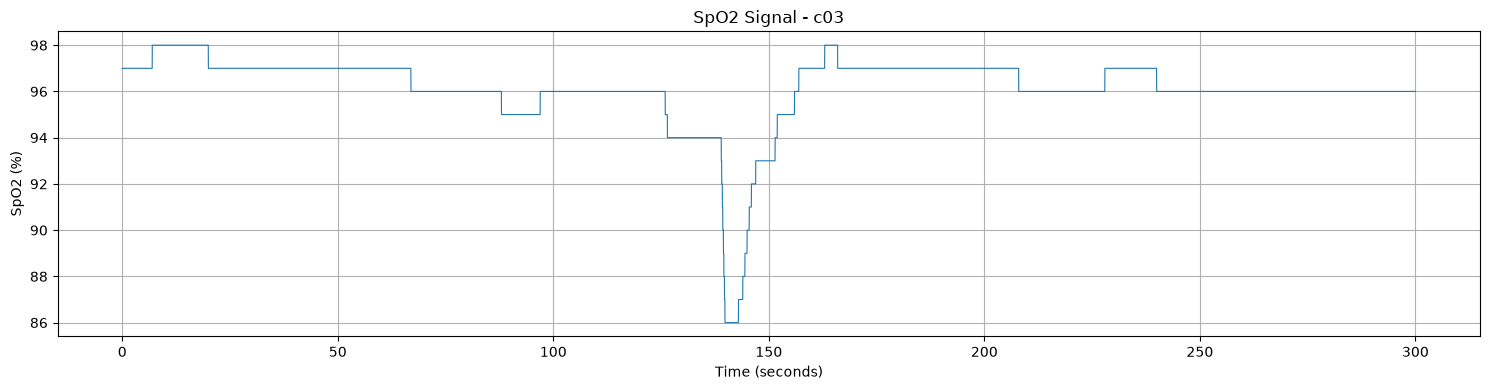

In [141]:

for name, data in spo2_data.items():

    signal = data["signal"]
    fs = data["fs"]

    # First 5 minutes
    samples = min(len(signal), int(5 * 60 * fs))

    time = np.arange(samples) / fs

    plt.figure(figsize=(15, 4))

    plt.plot(time, signal[:samples], linewidth=0.8)

    plt.title(f"SpO2 Signal - {name}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("SpO2 (%)")

    plt.grid(True)
    plt.tight_layout()
    plt.show()


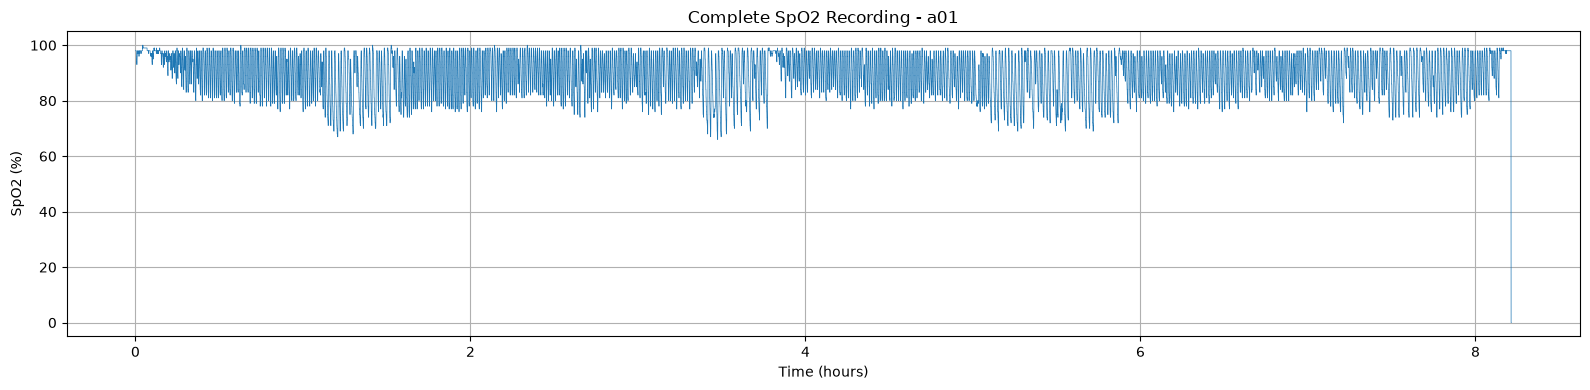

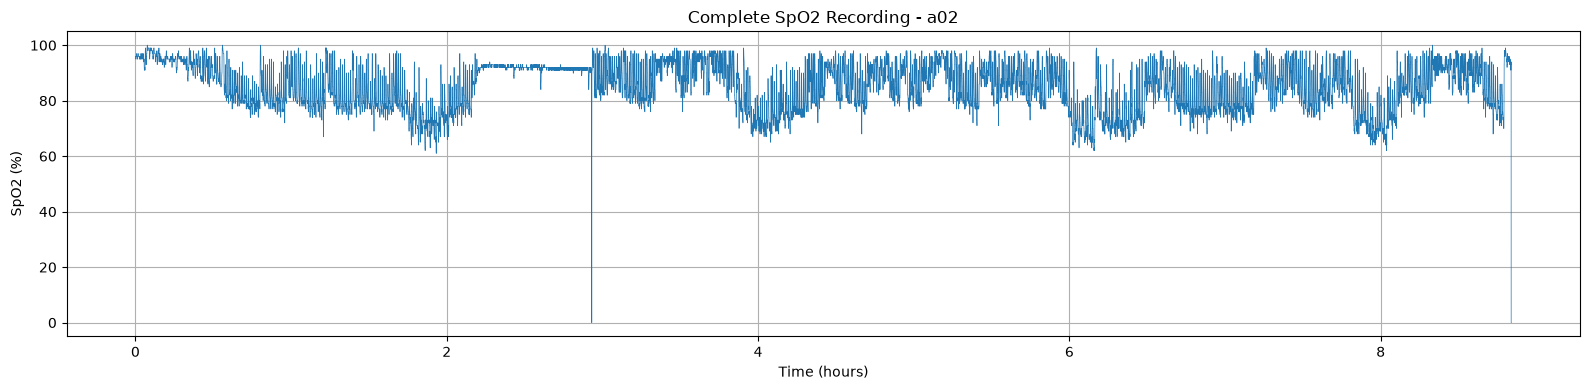

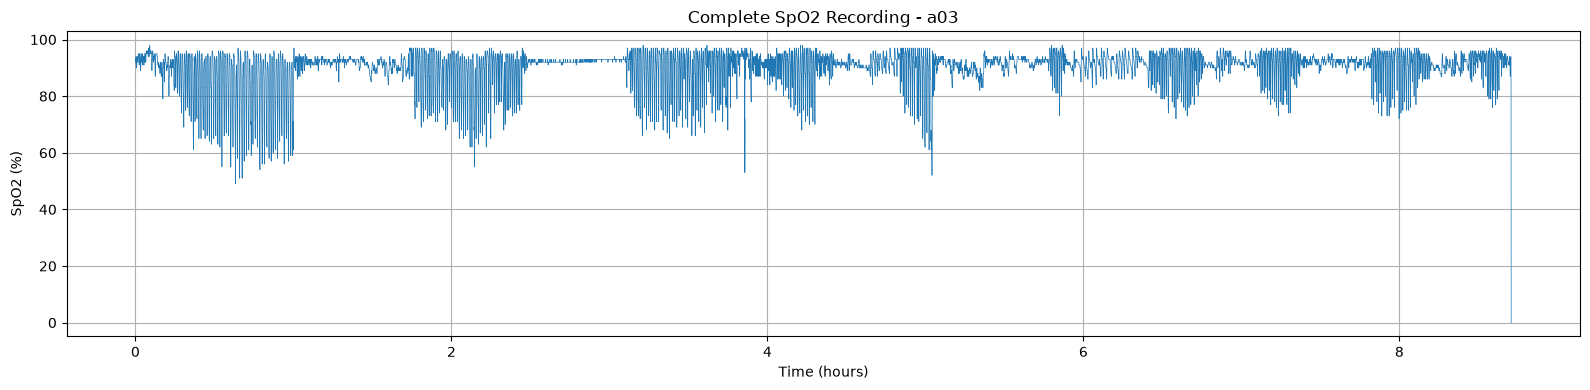

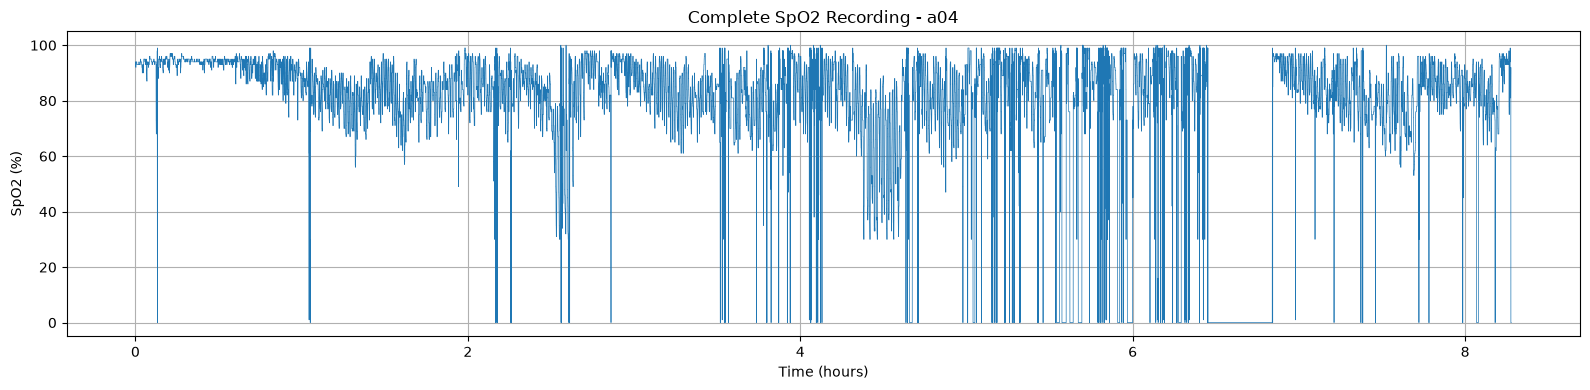

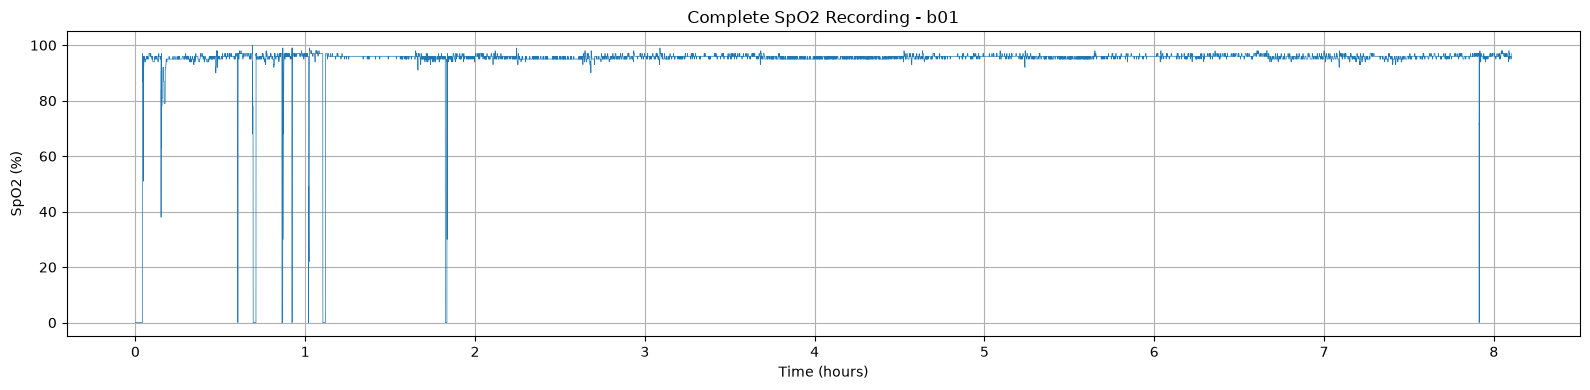

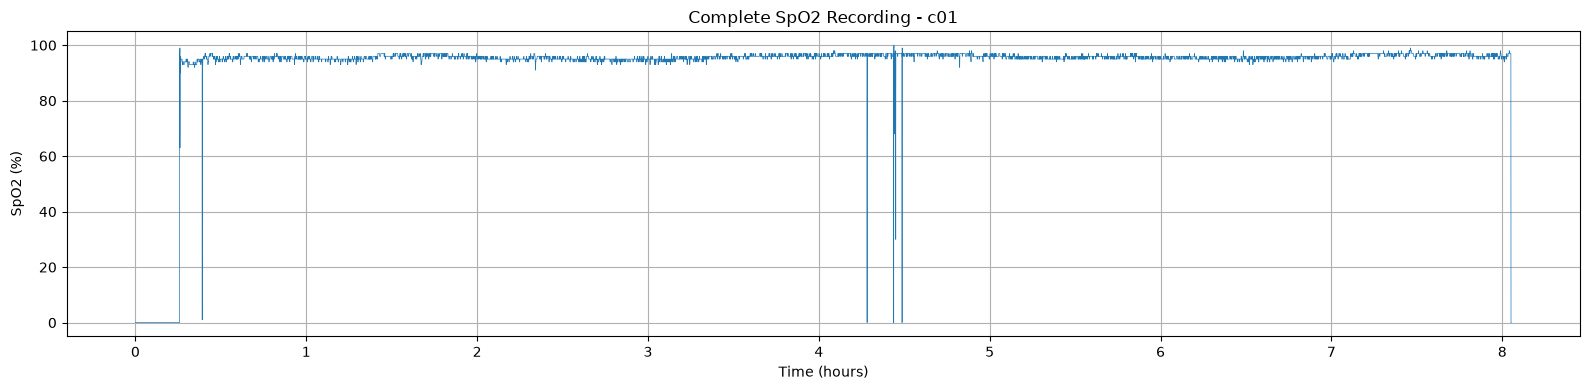

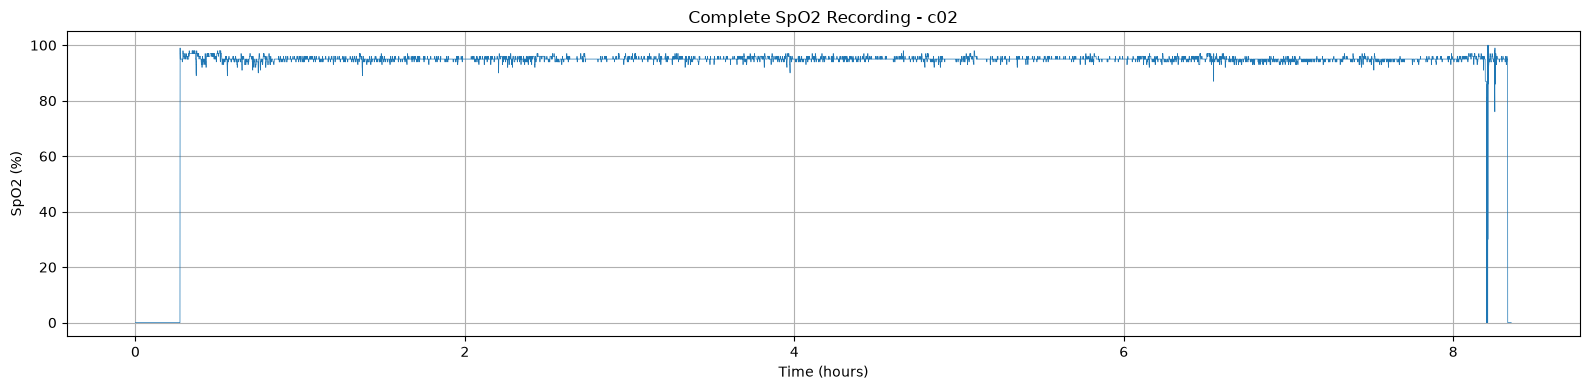

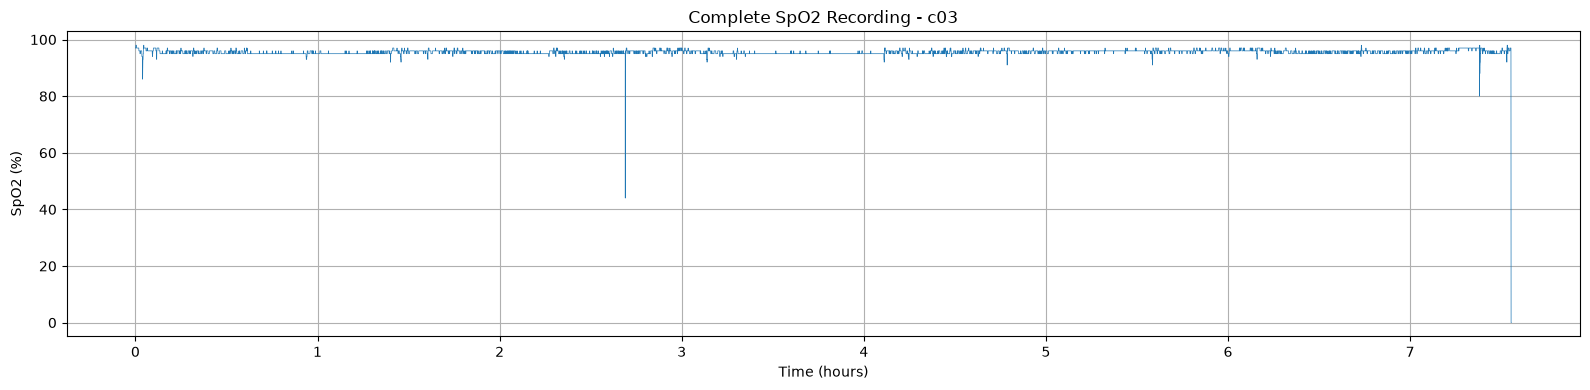

In [142]:

for name, data in spo2_data.items():

    signal = data["signal"]
    fs = data["fs"]

    time = np.arange(len(signal)) / fs

    plt.figure(figsize=(16, 4))

    plt.plot(time / 3600, signal, linewidth=0.5)

    plt.title(f"Complete SpO2 Recording - {name}")
    plt.xlabel("Time (hours)")
    plt.ylabel("SpO2 (%)")

    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [143]:

summary = []

for name, data in spo2_data.items():

    signal = data["signal"]
    valid = signal[np.isfinite(signal)]

    summary.append({
        "Record": name,
        "Sampling Frequency": data["fs"],
        "Total Samples": len(signal),
        "Duration (hours)": len(signal) / data["fs"] / 3600,
        "Missing Values": np.sum(~np.isfinite(signal)),
        "Minimum SpO2": np.min(valid),
        "Maximum SpO2": np.max(valid),
        "Mean SpO2": np.mean(valid),
        "Median SpO2": np.median(valid),
        "Standard Deviation": np.std(valid)
    })

summary_df = pd.DataFrame(summary)

display(summary_df.round(3))


,Record,Sampling Frequency,Total Samples,Duration (hours),Missing Values,Minimum SpO2,Maximum SpO2,Mean SpO2,Median SpO2,Standard Deviation
0,a01,100,2956796,8.213,0,0.0,100.0,89.543,91.0,7.603
1,a02,100,3181796,8.838,0,0.0,100.0,85.201,86.0,8.286
2,a03,100,3134796,8.708,0,0.0,98.0,90.040,92.0,6.377
3,a04,100,2979796,8.277,0,0.0,100.0,77.392,85.0,25.383
4,b01,100,2916796,8.102,0,0.0,100.0,94.542,96.0,10.252
5,c01,100,2898796,8.052,0,0.0,100.0,92.501,96.0,16.983
6,c02,100,3006796,8.352,0,0.0,100.0,91.530,95.0,17.624
7,c03,100,2719796,7.555,0,0.0,98.0,95.521,95.0,1.415


In [144]:

for name, data in spo2_data.items():

    signal = data["signal"]

    valid = np.isfinite(signal)

    # Invalid values
    invalid_count = np.sum(~valid)

    # Values outside plausible SpO2 range
    abnormal_count = np.sum(
        valid & ((signal < 50) | (signal > 100))
    )

    # Values below 90%
    low_count = np.sum(
        valid & (signal < 90)
    )

    print(f"\nRecord: {name}")
    print("Missing / non-finite values:", invalid_count)
    print("Outside 50–100%:", abnormal_count)
    print("Samples below 90%:", low_count)



Record: a01
Missing / non-finite values: 0
Outside 50–100%: 452
Samples below 90%: 1342381

Record: a02
Missing / non-finite values: 0
Outside 50–100%: 367
Samples below 90%: 1942379

Record: a03
Missing / non-finite values: 0
Outside 50–100%: 389
Samples below 90%: 817378

Record: a04
Missing / non-finite values: 0
Outside 50–100%: 296589
Samples below 90%: 1927296

Record: b01
Missing / non-finite values: 0
Outside 50–100%: 34566
Samples below 90%: 46362

Record: c01
Missing / non-finite values: 0
Outside 50–100%: 94510
Samples below 90%: 96060

Record: c02
Missing / non-finite values: 0
Outside 50–100%: 107486
Samples below 90%: 114647

Record: c03
Missing / non-finite values: 0
Outside 50–100%: 479
Samples below 90%: 1966


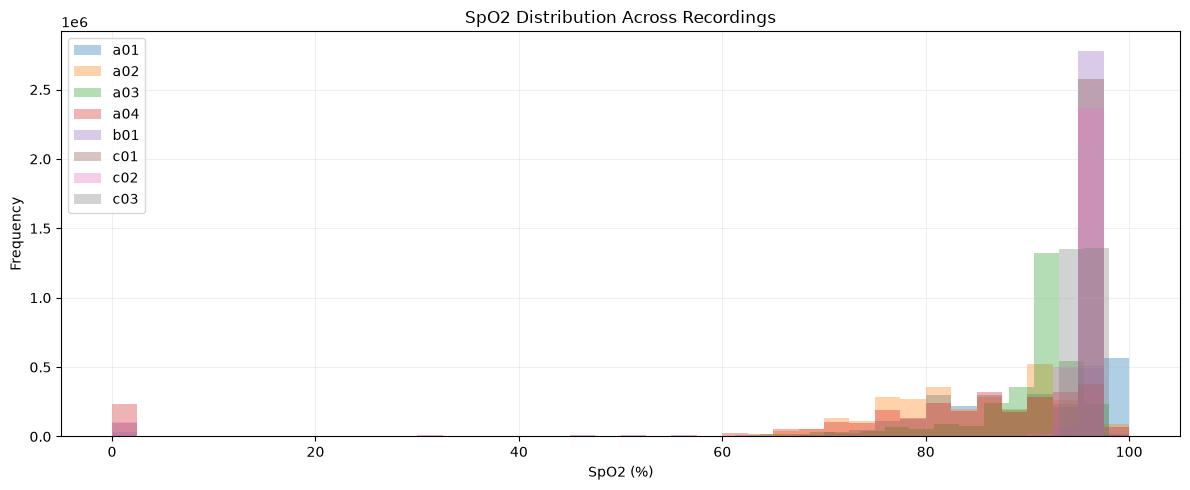

In [145]:

plt.figure(figsize=(12, 5))

for name, data in spo2_data.items():

    signal = data["signal"]
    valid = signal[np.isfinite(signal)]

    plt.hist(
        valid,
        bins=40,
        alpha=0.35,
        label=name
    )

plt.xlabel("SpO2 (%)")
plt.ylabel("Frequency")
plt.title("SpO2 Distribution Across Recordings")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [146]:

for name, data in spo2_data.items():

    signal = data["signal"]
    valid = np.isfinite(signal)

    print("\n" + "=" * 40)
    print("Record:", name)

    print("Exactly zero:", np.sum(signal == 0))
    print("Below 50:", np.sum(valid & (signal < 50)))
    print("Between 50 and 90:", np.sum(valid & (signal >= 50) & (signal < 90)))
    print("Between 90 and 100:", np.sum(valid & (signal >= 90) & (signal <= 100)))
    print("Above 100:", np.sum(valid & (signal > 100)))

    suspicious = signal[valid & ((signal < 50) | (signal > 100))]

    if len(suspicious):
        print("Most frequent suspicious values:")
        print(
            pd.Series(suspicious)
            .value_counts()
            .head(10)
        )



Record: a01
Exactly zero: 402
Below 50: 452
Between 50 and 90: 1341929
Between 90 and 100: 1614415
Above 100: 0
Most frequent suspicious values:
0.0     402
49.0      2
46.0      2
44.0      2
41.0      2
39.0      2
36.0      2
34.0      2
31.0      2
29.0      2
Name: count, dtype: int64

Record: a02
Exactly zero: 205
Below 50: 367
Between 50 and 90: 1942012
Between 90 and 100: 1239417
Above 100: 0
Most frequent suspicious values:
0.0     205
42.0      6
49.0      5
45.0      5
28.0      5
6.0       5
4.0       5
47.0      4
40.0      4
39.0      4
Name: count, dtype: int64

Record: a03
Exactly zero: 202
Below 50: 389
Between 50 and 90: 816989
Between 90 and 100: 2317418
Above 100: 0
Most frequent suspicious values:
0.0     202
49.0    135
46.0      2
43.0      2
41.0      2
38.0      2
36.0      2
32.0      2
29.0      2
27.0      2
Name: count, dtype: int64

Record: a04
Exactly zero: 232032
Below 50: 296589
Between 50 and 90: 1630707
Between 90 and 100: 1052500
Above 100: 0
Most f

In [147]:

for name, data in spo2_data.items():

    signal = data["signal"]
    fs = data["fs"]

    # Treat values outside 50–100 as suspicious for now
    bad = (
        (~np.isfinite(signal)) |
        (signal < 50) |
        (signal > 100)
    )

    # Find start and end of each continuous region
    changes = np.diff(
        np.r_[False, bad, False].astype(int)
    )

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    runs = []

    for start, end in zip(starts, ends):
        duration = (end - start) / fs

        runs.append({
            "start_min": start / fs / 60,
            "end_min": end / fs / 60,
            "duration_sec": duration
        })

    runs.sort(
        key=lambda x: x["duration_sec"],
        reverse=True
    )

    print(f"\nRecord: {name}")
    print("Total invalid regions:", len(runs))

    for run in runs[:5]:
        print(run)



Record: a01
Total invalid regions: 1
{'start_min': np.float64(492.724), 'end_min': np.float64(492.7993333333333), 'duration_sec': np.float64(4.52)}

Record: a02
Total invalid regions: 2
{'start_min': np.float64(175.87316666666666), 'end_min': np.float64(175.90866666666668), 'duration_sec': np.float64(2.13)}
{'start_min': np.float64(530.2736666666666), 'end_min': np.float64(530.2993333333333), 'duration_sec': np.float64(1.54)}

Record: a03
Total invalid regions: 2
{'start_min': np.float64(522.4235), 'end_min': np.float64(522.466), 'duration_sec': np.float64(2.55)}
{'start_min': np.float64(37.993500000000004), 'end_min': np.float64(38.01583333333333), 'duration_sec': np.float64(1.34)}

Record: a04
Total invalid regions: 179
{'start_min': np.float64(387.1573333333333), 'end_min': np.float64(410.3745), 'duration_sec': np.float64(1393.03)}
{'start_min': np.float64(358.02116666666666), 'end_min': np.float64(359.9773333333333), 'duration_sec': np.float64(117.37)}
{'start_min': np.float64(334

In [148]:

for name in records:

    record_name = name + "r"

    record = wfdb.rdrecord(
        str(SPO2_PATH / record_name)
    )

    print("\nRecord:", record_name)
    print("Channel names:", record.sig_name)
    print("Units:", record.units)
    print("Sampling frequency:", record.fs)
    print("ADC gains:", record.adc_gain)
    print("Baselines:", record.baseline)
    print("ADC resolution:", record.adc_res)



Record: a01r
Channel names: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Sampling frequency: 100
ADC gains: [20000.0, 20000.0, 20000.0, 1.0]
Baselines: [0, 0, 0, 0]
ADC resolution: [16, 16, 16, 16]

Record: a02r
Channel names: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Sampling frequency: 100
ADC gains: [20000.0, 20000.0, 20000.0, 1.0]
Baselines: [0, 0, 0, 0]
ADC resolution: [16, 16, 16, 16]

Record: a03r
Channel names: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Sampling frequency: 100
ADC gains: [20000.0, 20000.0, 20000.0, 1.0]
Baselines: [0, 0, 0, 0]
ADC resolution: [16, 16, 16, 16]

Record: a04r
Channel names: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']
Sampling frequency: 100
ADC gains: [20000.0, 20000.0, 20000.0, 1.0]
Baselines: [0, 0, 0, 0]
ADC resolution: [16, 16, 16, 16]

Record: b01r
Channel names: ['Resp C', 'Resp A', 'Resp N', 'SpO2']
Units: ['mV', 'mV', 'mV', 'mV']


In [149]:
import numpy as np
import pandas as pd

minute_quality = {}

for name, data in spo2_data.items():
    signal = data["signal"]
    fs = data["fs"]

    samples_per_minute = int(fs * 60)

    # Mark suspicious readings
    invalid = (
        (~np.isfinite(signal)) |
        (signal < 50) |
        (signal > 100)
    )

    rows = []

    for minute, start in enumerate(
        range(0, len(signal), samples_per_minute)
    ):
        end = min(start + samples_per_minute, len(signal))

        invalid_count = np.sum(invalid[start:end])
        total_count = end - start

        invalid_percentage = (
            invalid_count / total_count
        ) * 100

        rows.append({
            "minute": minute,
            "invalid_samples": invalid_count,
            "total_samples": total_count,
            "invalid_percentage": invalid_percentage
        })

    df = pd.DataFrame(rows)
    minute_quality[name] = df

    affected = df[df["invalid_percentage"] > 5]

    print(f"\nRecord: {name}")
    print("Total one-minute windows:", len(df))
    print("Windows with >5% invalid samples:", len(affected))
    print(affected.head(15).to_string(index=False))


Record: a01
Total one-minute windows: 493
Windows with >5% invalid samples: 1
 minute  invalid_samples  total_samples  invalid_percentage
    492              452           4796             9.42452

Record: a02
Total one-minute windows: 531
Windows with >5% invalid samples: 1
 minute  invalid_samples  total_samples  invalid_percentage
    530              154           1796             8.57461

Record: a03
Total one-minute windows: 523
Windows with >5% invalid samples: 1
 minute  invalid_samples  total_samples  invalid_percentage
    522              255           2796            9.120172

Record: a04
Total one-minute windows: 497
Windows with >5% invalid samples: 119
 minute  invalid_samples  total_samples  invalid_percentage
     62              349           6000            5.816667
     63              764           6000           12.733333
    129              380           6000            6.333333
    130              513           6000            8.550000
    135              7

In [150]:
for name in records:
    record_name = name + "r"

    ann = wfdb.rdann(
        str(SPO2_PATH / record_name),
        "apn"
    )

    print(f"\nRecord: {record_name}")
    print("Number of annotations:", len(ann.sample))
    print("First 10 annotation positions:", ann.sample[:10])
    print("First 10 annotation symbols:", ann.symbol[:10])


Record: a01r
Number of annotations: 489
First 10 annotation positions: [    0  6000 12000 18000 24000 30000 36000 42000 48000 54000]
First 10 annotation symbols: ['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']

Record: a02r
Number of annotations: 528
First 10 annotation positions: [    0  6000 12000 18000 24000 30000 36000 42000 48000 54000]
First 10 annotation symbols: ['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']

Record: a03r
Number of annotations: 519
First 10 annotation positions: [    0  6000 12000 18000 24000 30000 36000 42000 48000 54000]
First 10 annotation symbols: ['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']

Record: a04r
Number of annotations: 492
First 10 annotation positions: [    0  6000 12000 18000 24000 30000 36000 42000 48000 54000]
First 10 annotation symbols: ['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']

Record: b01r
Number of annotations: 487
First 10 annotation positions: [    0  6000 12000 18000 24000 30000 36000 42000 48000 54000]
First 10 a

In [151]:
import numpy as np
import pandas as pd
import wfdb

spo2_windows = []
spo2_labels = []
spo2_metadata = []

samples_per_minute = 60 * 100
MAX_INVALID_PERCENTAGE = 5

for name in records:

    record_name = name + "r"

    signal = spo2_data[name]["signal"]

    # Load apnea annotations
    ann = wfdb.rdann(
        str(SPO2_PATH / record_name),
        "apn"
    )

    kept = 0
    rejected = 0

    for start, symbol in zip(ann.sample, ann.symbol):

        end = start + samples_per_minute

        # Ensure a complete 60-second window exists
        if end > len(signal):
            continue

        # Extract one-minute window
        window = signal[start:end].copy()

        # Identify invalid samples
        valid_mask = (
            np.isfinite(window) &
            (window >= 50) &
            (window <= 100)
        )

        invalid_percentage = (
            1 - np.mean(valid_mask)
        ) * 100

        # Reject windows with too many invalid samples
        if invalid_percentage > MAX_INVALID_PERCENTAGE:
            rejected += 1
            continue

        # Interpolate small gaps
        valid_indices = np.where(valid_mask)[0]
        invalid_indices = np.where(~valid_mask)[0]

        if len(invalid_indices) > 0:
            window[invalid_indices] = np.interp(
                invalid_indices,
                valid_indices,
                window[valid_indices]
            )

        # Convert annotation into binary label
        if symbol == "A":
            label = 1
        elif symbol == "N":
            label = 0
        else:
            continue

        spo2_windows.append(window)
        spo2_labels.append(label)

        spo2_metadata.append({
            "record": name,
            "start_sample": start,
            "label": label,
            "invalid_percentage": invalid_percentage
        })

        kept += 1

    print(
        f"{name}: Kept = {kept}, "
        f"Rejected = {rejected}"
    )

# Convert to NumPy arrays
X_spo2 = np.array(spo2_windows, dtype=np.float32)
y_spo2 = np.array(spo2_labels, dtype=np.int32)

metadata_df = pd.DataFrame(spo2_metadata)

print("\nFinal dataset shape:", X_spo2.shape)
print("Labels shape:", y_spo2.shape)

print("\nClass distribution:")
print(pd.Series(y_spo2).value_counts().rename({
    0: "Normal",
    1: "Apnea"
}))

a01: Kept = 489, Rejected = 0
a02: Kept = 528, Rejected = 0
a03: Kept = 519, Rejected = 0
a04: Kept = 374, Rejected = 118
b01: Kept = 473, Rejected = 13
c01: Kept = 466, Rejected = 17
c02: Kept = 481, Rejected = 20
c03: Kept = 453, Rejected = 0

Final dataset shape: (3783, 6000)
Labels shape: (3783,)

Class distribution:
Normal    2291
Apnea     1492
Name: count, dtype: int64


In [152]:
print("Dataset shape:", X_spo2.shape)

print("\nMissing values:", np.isnan(X_spo2).sum())

print("Minimum SpO2:", X_spo2.min())
print("Maximum SpO2:", X_spo2.max())

print("\nLabels:")
print("Normal:", np.sum(y_spo2 == 0))
print("Apnea:", np.sum(y_spo2 == 1))

print("\nWindows per record:")
print(metadata_df["record"].value_counts())

print("\nInvalid percentage summary:")
print(metadata_df["invalid_percentage"].describe())

Dataset shape: (3783, 6000)

Missing values: 0
Minimum SpO2: 50.0
Maximum SpO2: 100.0

Labels:
Normal: 2291
Apnea: 1492

Windows per record:
record
a02    528
a03    519
a01    489
c02    481
b01    473
c01    466
c03    453
a04    374
Name: count, dtype: int64

Invalid percentage summary:
count    3783.000000
mean        0.020680
std         0.253005
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         4.500000
Name: invalid_percentage, dtype: float64


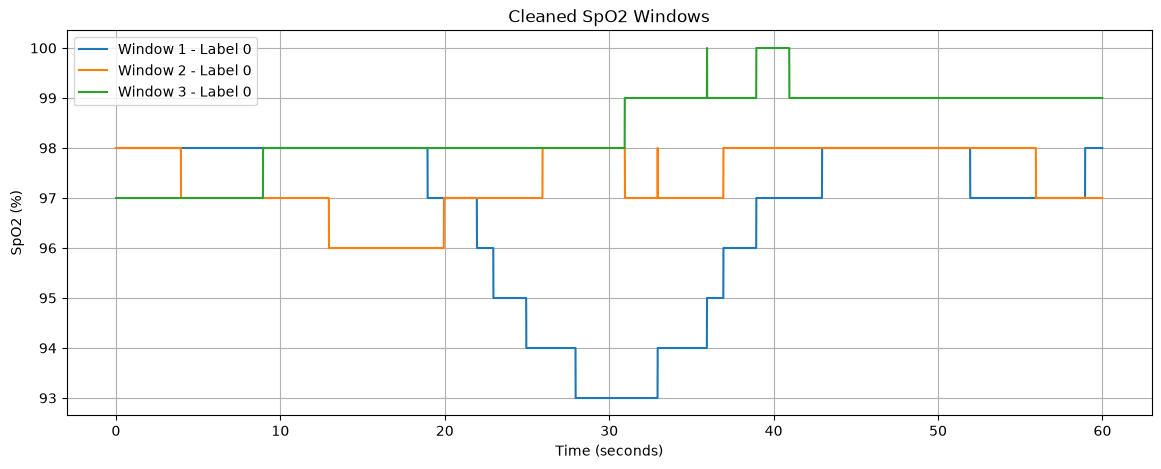

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

for i in range(3):
    plt.plot(
        np.arange(samples_per_minute) / 100,
        X_spo2[i],
        label=f"Window {i+1} - Label {y_spo2[i]}"
    )

plt.xlabel("Time (seconds)")
plt.ylabel("SpO2 (%)")
plt.title("Cleaned SpO2 Windows")
plt.legend()
plt.grid()
plt.show()

In [154]:
record_distribution = pd.crosstab(
    metadata_df["record"],
    metadata_df["label"]
)

record_distribution = record_distribution.rename(
    columns={0: "Normal", 1: "Apnea"}
)

record_distribution["Total"] = record_distribution.sum(axis=1)

print(record_distribution)

label   Normal  Apnea  Total
record                      
a01         19    470    489
a02        108    420    528
a03        273    246    519
a04         38    336    374
b01        454     19    473
c01        466      0    466
c02        480      1    481
c03        453      0    453


In [155]:
# Each window: 6000 samples = 60 seconds × 100 samples
# Reshape into 60 groups, each containing 100 samples

X_spo2_1hz = np.median(
    X_spo2.reshape(-1, 60, 100),
    axis=2
)

X_spo2_1hz = X_spo2_1hz.astype(np.float32)

print("Original shape:", X_spo2.shape)
print("Reduced shape:", X_spo2_1hz.shape)

Original shape: (3783, 6000)
Reduced shape: (3783, 60)


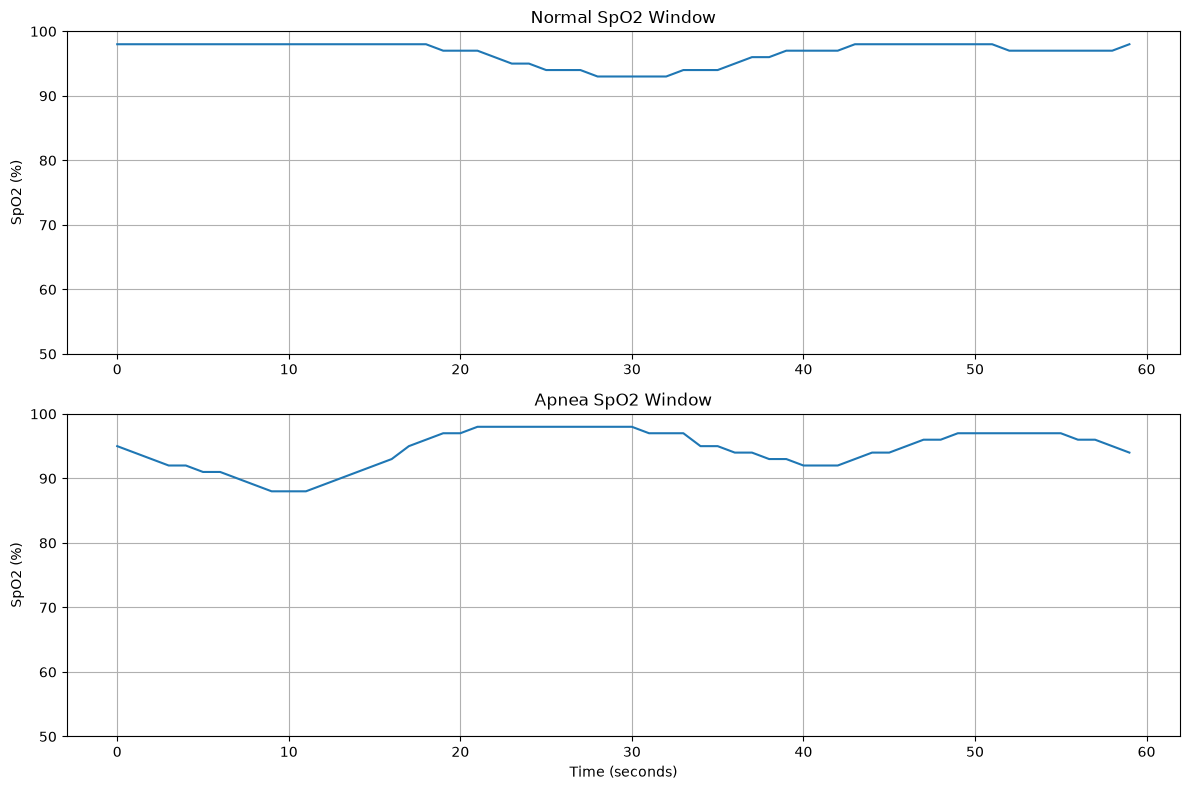

In [156]:
normal_idx = np.where(y_spo2 == 0)[0]
apnea_idx = np.where(y_spo2 == 1)[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(X_spo2_1hz[normal_idx[0]])
axes[0].set_title("Normal SpO2 Window")
axes[0].set_ylabel("SpO2 (%)")
axes[0].set_ylim(50, 100)
axes[0].grid()

axes[1].plot(X_spo2_1hz[apnea_idx[0]])
axes[1].set_title("Apnea SpO2 Window")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("SpO2 (%)")
axes[1].set_ylim(50, 100)
axes[1].grid()

plt.tight_layout()
plt.show()

In [157]:
train_records = ["a01", "a02", "c01", "c02", "c03"]
val_records = ["a03"]
test_records = ["a04", "b01"]

train_mask = metadata_df["record"].isin(train_records).values
val_mask = metadata_df["record"].isin(val_records).values
test_mask = metadata_df["record"].isin(test_records).values

X_train = X_spo2_1hz[train_mask]
y_train = y_spo2[train_mask]

X_val = X_spo2_1hz[val_mask]
y_val = y_spo2[val_mask]

X_test = X_spo2_1hz[test_mask]
y_test = y_spo2[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (2417, 60)
Validation: (519, 60)
Testing: (847, 60)


In [158]:
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}")
    print("Normal:", np.sum(labels == 0))
    print("Apnea:", np.sum(labels == 1))


Training
Normal: 1526
Apnea: 891

Validation
Normal: 273
Apnea: 246

Testing
Normal: 492
Apnea: 355


In [159]:
mean = X_train.mean()
std = X_train.std()

X_train_norm = (X_train - mean) / (std + 1e-8)
X_val_norm = (X_val - mean) / (std + 1e-8)
X_test_norm = (X_test - mean) / (std + 1e-8)

# CNN expects: (samples, time steps, channels)
X_train_cnn = X_train_norm[..., np.newaxis]
X_val_cnn = X_val_norm[..., np.newaxis]
X_test_cnn = X_test_norm[..., np.newaxis]

print("CNN training shape:", X_train_cnn.shape)
print("CNN validation shape:", X_val_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)

CNN training shape: (2417, 60, 1)
CNN validation shape: (519, 60, 1)
CNN testing shape: (847, 60, 1)


# SpO₂ CNN Training (uses the preprocessing above)

Run this section **in the same notebook and kernel** after the original preprocessing cells have completed. It uses the existing in-memory variables `X_spo2_1hz`, `y_spo2`, `metadata_df`, `train_records`, `val_records`, and `test_records`. No raw files, export file, or second preprocessing run is needed.

The original preprocessing and its patient split are left unchanged. The CNN input is `(60, 1)`, because the original preprocessing converts each 60-second, 6,000-sample window into 60 one-second median values.

## CNN 1. Import training libraries

In [160]:
import json
from pathlib import Path

import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
    precision_recall_fscore_support
)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## CNN 2. Verify that preprocessing variables exist

In [161]:
required_variables = [
    "X_spo2_1hz", "y_spo2", "metadata_df",
    "train_records", "val_records", "test_records"
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(
        "Run the original preprocessing notebook cells through the patient split "
        "(including the normalization/split cell) before running this section. "
        f"Missing variables: {missing_variables}"
    )

X_spo2_1hz = np.asarray(X_spo2_1hz, dtype=np.float32)
y_spo2 = np.asarray(y_spo2, dtype=np.int32)
record_ids = metadata_df["record"].astype(str).to_numpy()
start_samples = metadata_df["start_sample"].to_numpy(dtype=np.int64)

assert X_spo2_1hz.ndim == 2 and X_spo2_1hz.shape[1] == 60
assert len(X_spo2_1hz) == len(y_spo2) == len(record_ids) == len(start_samples)
assert np.isfinite(X_spo2_1hz).all()
assert set(np.unique(y_spo2)).issubset({0, 1})

print("Data shape:", X_spo2_1hz.shape)
print("Labels:", y_spo2.shape)
print("Records:", sorted(np.unique(record_ids).tolist()))
print("Train records:", train_records)
print("Validation records:", val_records)
print("Test records:", test_records)

Data shape: (3783, 60)
Labels: (3783,)
Records: ['a01', 'a02', 'a03', 'a04', 'b01', 'c01', 'c02', 'c03']
Train records: ['a01', 'a02', 'c01', 'c02', 'c03']
Validation records: ['a03']
Test records: ['a04', 'b01']


## CNN 3. Create train, validation and test sets

In [162]:
train_mask = np.isin(record_ids, train_records)
val_mask = np.isin(record_ids, val_records)
test_mask = np.isin(record_ids, test_records)

X_train, y_train = X_spo2_1hz[train_mask], y_spo2[train_mask]
X_val, y_val = X_spo2_1hz[val_mask], y_spo2[val_mask]
X_test, y_test = X_spo2_1hz[test_mask], y_spo2[test_mask]

assert len(X_train) and len(X_val) and len(X_test)
assert set(record_ids[train_mask]).isdisjoint(set(record_ids[val_mask]))
assert set(record_ids[train_mask]).isdisjoint(set(record_ids[test_mask]))
assert set(record_ids[val_mask]).isdisjoint(set(record_ids[test_mask]))

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (2417, 60) (2417,)
Validation: (519, 60) (519,)
Testing: (847, 60) (847,)


## CNN 4. Normalize and reshape

This follows the normalization approach in the original preprocessing notebook: use the training partition's mean and standard deviation, then apply those same values to validation and test.

In [163]:
mean = float(X_train.mean())
std = float(X_train.std())

X_train_norm = (X_train - mean) / (std + 1e-8)
X_val_norm = (X_val - mean) / (std + 1e-8)
X_test_norm = (X_test - mean) / (std + 1e-8)

X_train_cnn = X_train_norm[..., np.newaxis].astype(np.float32)
X_val_cnn = X_val_norm[..., np.newaxis].astype(np.float32)
X_test_cnn = X_test_norm[..., np.newaxis].astype(np.float32)

print("CNN training shape:", X_train_cnn.shape)
print("CNN validation shape:", X_val_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)
print("Training mean:", mean)
print("Training standard deviation:", std)

CNN training shape: (2417, 60, 1)
CNN validation shape: (519, 60, 1)
CNN testing shape: (847, 60, 1)
Training mean: 91.94778442382812
Training standard deviation: 6.690342903137207


## CNN 5. Calculate class weights

In [164]:
classes = np.unique(y_train)
if len(classes) < 2:
    raise ValueError(f"Training data must contain both classes. Found: {classes}")

weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}
print("Class weights:", class_weights)

Class weights: {0: 0.7919397116644823, 1: 1.356341189674523}


## CNN 6. Build the SpO₂ CNN

The input shape follows the original preprocessing output: `(60, 1)`. The convolutional filter counts and kernel sizes are retained: 32/64/64 filters and kernels 7/5/3.

In [172]:
from tensorflow.keras import regularizers
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D,
    Dense, Dropout, BatchNormalization
)

def build_spo2_cnn():

    model = Sequential([

        Input(shape=(60, 1)),

        # First convolution block
        Conv1D(
            16, 5,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(0.0001)
        ),

        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        # Second convolution block
        Conv1D(
            32, 3,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(0.0001)
        ),

        BatchNormalization(),

        GlobalAveragePooling1D(),

        # Classification block
        Dense(
            16,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.0001)
        ),

        Dropout(0.25),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0003
        ),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model


model = build_spo2_cnn()
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_15 (Conv1D)                   │ (None, 60, 16)              │              96 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 60, 16)              │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_8 (MaxPooling1D)       │ (None, 30, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_16 (Conv1D)                   │ (None, 30, 32)              │           1,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 30, 32)              │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_7           │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,401 (9.38 KB)

 Trainable params: 2,305 (9.00 KB)

 Non-trainable params: 96 (384.00 B)

## CNN 7. Train

In [173]:
OUTPUT_DIR = Path("../results/final_model")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
best_model_path = OUTPUT_DIR / "spo2_cnn_best.keras"

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        str(best_model_path),
        monitor="val_loss",
        save_best_only=True
    )
]

In [174]:
history = model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=30,
    batch_size=16,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.8751 - auc: 0.9441 - loss: 0.3721 - val_accuracy: 0.6975 - val_auc: 0.7895 - val_loss: 0.6433 - learning_rate: 3.0000e-04
Epoch 2/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9764 - auc: 0.9914 - loss: 0.1575 - val_accuracy: 0.7264 - val_auc: 0.8149 - val_loss: 0.5669 - learning_rate: 3.0000e-04
Epoch 3/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9702 - auc: 0.9901 - loss: 0.1270 - val_accuracy: 0.7881 - val_auc: 0.8813 - val_loss: 0.4613 - learning_rate: 3.0000e-04
Epoch 4/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9731 - auc: 0.9911 - loss: 0.1099 - val_accuracy: 0.8420 - val_auc: 0.9333 - val_loss: 0.3766 - learning_rate: 3.0000e-04
Epoch 5/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9752 - auc: 0.9960 - loss: 0.0864 - val_accuracy: 0.8960 - val_auc: 0.9537 - val_loss: 0.2864 - learning_rate: 3.0000e-04
Epoch 6/30
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step -

## CNN 8. Plot training history

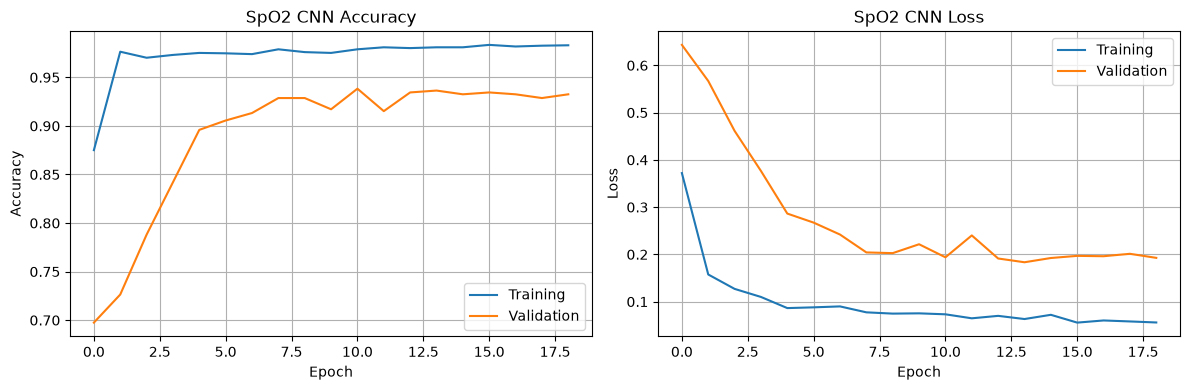

In [175]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("SpO2 CNN Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title("SpO2 CNN Loss")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

## CNN 9. Select threshold using validation data

In [176]:
val_prob = model.predict(X_val_cnn, verbose=0).ravel()
threshold_results = []

for candidate in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    candidate_pred = (val_prob >= candidate).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, candidate_pred, average="binary", zero_division=0
    )
    threshold_results.append({
        "threshold": candidate,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy_score(y_val, candidate_pred)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))
threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print("Selected threshold:", threshold)

,threshold,precision,recall,f1,accuracy
0,0.30,0.9216,0.9553,0.9381,0.9403
1,0.35,0.9388,0.9350,0.9369,0.9403
2,0.40,0.9461,0.9268,0.9363,0.9403
3,0.45,0.9494,0.9146,0.9317,0.9364
4,0.50,0.9571,0.9065,0.9311,0.9364
5,0.55,0.9605,0.8902,0.9241,0.9306
6,0.60,0.9688,0.8821,0.9234,0.9306
7,0.65,0.9686,0.8780,0.9211,0.9287
8,0.70,0.9682,0.8659,0.9142,0.9229


Selected threshold: 0.3


## CNN 10. Evaluate on held-out test records

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9374 - auc: 0.9648 - loss: 0.2791
Test loss: 0.2791
Test accuracy: 0.9374
Test ROC-AUC: 0.9648

Accuracy: 0.9504
ROC-AUC: 0.9795

               precision    recall  f1-score   support

      Normal       0.93      0.99      0.96       492
       Apnea       0.98      0.90      0.94       355

    accuracy                           0.95       847
   macro avg       0.96      0.94      0.95       847
weighted avg       0.95      0.95      0.95       847



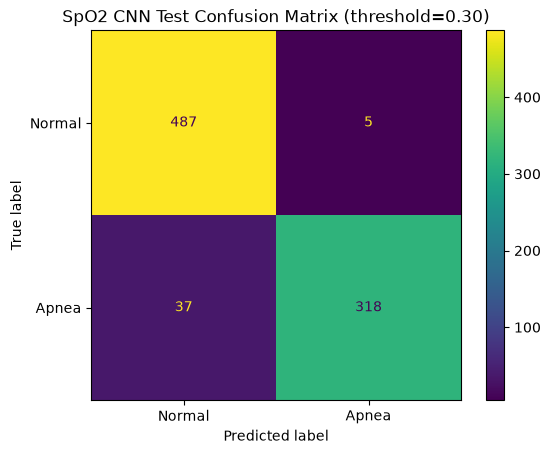

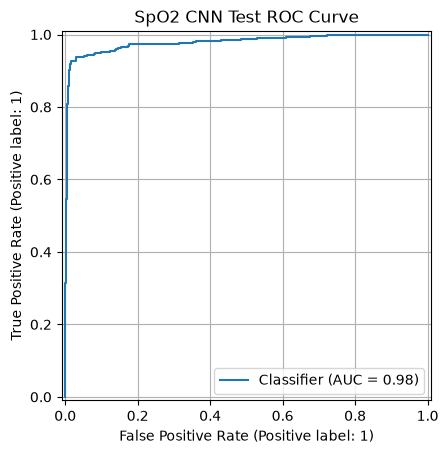

In [177]:
test_results = model.evaluate(X_test_cnn, y_test, verbose=1, return_dict=True)
print(f"Test loss: {test_results['loss']:.4f}")
print(f"Test accuracy: {test_results['accuracy']:.4f}")
print(f"Test ROC-AUC: {test_results['auc']:.4f}")

y_true = y_test.astype(int).ravel()
y_prob = model.predict(X_test_cnn, verbose=0).ravel()
y_pred = (y_prob >= threshold).astype(int)

print("\nAccuracy:", round(accuracy_score(y_true, y_pred), 4))
if len(np.unique(y_true)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
print("\n", classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=["Normal", "Apnea"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1],
    display_labels=["Normal", "Apnea"]
)
plt.title(f"SpO2 CNN Test Confusion Matrix (threshold={threshold:.2f})")
plt.show()

if len(np.unique(y_true)) == 2:
    RocCurveDisplay.from_predictions(y_true, y_prob)
    plt.title("SpO2 CNN Test ROC Curve")
    plt.grid(True)
    plt.show()

## CNN 11. Save model and patient/time-aligned predictions

In [178]:
model.save(OUTPUT_DIR / "spo2_cnn.keras")

config = {
    "modality": "SpO2",
    "input_shape": [60, 1],
    "preprocessing": "original SpO2 preprocessing notebook, including median aggregation to 1 Hz",
    "normalization": "training-set global mean and standard deviation",
    "normalization_mean": mean,
    "normalization_std": std,
    "threshold": threshold,
    "train_records": list(train_records),
    "validation_records": list(val_records),
    "test_records": list(test_records),
    "conv_filters": [32, 64, 64],
    "kernel_sizes": [7, 5, 3],
    "pool_size": 4,
    "dense_units": 32,
    "dropout": 0.2
}
with open(OUTPUT_DIR / "spo2_model_config.json", "w") as f:
    json.dump(config, f, indent=4)

def export_split(mask, split_name, probabilities):
    idx = np.flatnonzero(mask)
    probabilities = np.asarray(probabilities).ravel()
    predictions = (probabilities >= threshold).astype(int)
    return pd.DataFrame({
        "record": record_ids[idx],
        "start_sample": start_samples[idx],
        "split": split_name,
        "true_label": y_spo2[idx],
        "probability_apnea": probabilities,
        "prediction": predictions
    })

train_prob = model.predict(X_train_cnn, verbose=0).ravel()
val_prob_export = model.predict(X_val_cnn, verbose=0).ravel()

train_export = export_split(train_mask, "train", train_prob)
val_export = export_split(val_mask, "validation", val_prob_export)
test_export = export_split(test_mask, "test", y_prob)

all_predictions = pd.concat([train_export, val_export, test_export], ignore_index=True)
all_predictions.to_csv(OUTPUT_DIR / "spo2_cnn_predictions_all_splits.csv", index=False)
test_export.to_csv(OUTPUT_DIR / "spo2_test_predictions.csv", index=False)

print("Saved model, config and prediction CSVs to:", OUTPUT_DIR.resolve())

Saved model, config and prediction CSVs to: C:\Users\navee\sleep-apnea-signal-analysis\results\final_model
